In [1]:
# # selection of 100 trees, le random state sera determiné de façon random verifiable le Vendredi matin

# import pandas as pd
# import random

# df = pd.read_csv('../data/arbres_grenoble_epsg4326.csv', sep=',', encoding='utf-8')
# df.dropna(subset=['anneedeplantation'], inplace=True)

# random_state = 28
# print(f"Random state generated: {random_state}")
# df_sample = df.sample(n=100, random_state=random_state)
# df_sample.to_csv('../selection_100_arbres.csv', index=False, encoding='utf-8')


In [2]:
# Les libraries nécessaires
import pandas as pd
import seaborn as sns
import numpy as np
import scipy.stats as sp
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

from sklearn.compose import ColumnTransformer

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, cross_validate
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.linear_model import LassoCV, Ridge

from sklearn.feature_selection import SelectFromModel

from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

from sklearn.tree import DecisionTreeRegressor

from tabicl import TabICLRegressor

In [3]:
# Colonnes retenues (choix justifiés dans ML10 et ML12)
FEATURES = ['sous_categorie', 'adr_secteur', 'stadededeveloppement', 'hauteurarbre',
            'structure', 'typenature', 'Latitude', 'Longitude', 'taxon']
CIBLE = 'anneedeplantation'


def preparer(df_brut):
    """Nettoie un DataFrame brut (format du CSV) et renvoie (X, y)."""
    df = df_brut.dropna(subset=[CIBLE]).copy()

    # Coordonnées
    coords = df['geo_point_2d'].str.split(',', expand=True).astype(float)
    df['Latitude'], df['Longitude'] = coords[0], coords[1]

    # Types et nouvelles variables
    df['adr_secteur'] = df['adr_secteur'].astype(str)
    df['taxon'] = df['genre_bota'] + ' ' + df['espece'].fillna('sp.')

    # Variables ordonnées (on garde aussi les colonnes texte d'origine)
    ordre_stade   = {'Arbre jeune': 1, 'Arbre adulte': 2, 'Arbre vieillissant': 3}
    ordre_hauteur = {'Moins de 10 m': 1, 'de 10 m à 20 m': 2, 'Plus de 20 m': 3}
    df['stade_ordre']   = df['stadededeveloppement'].map(ordre_stade)
    df['hauteur_ordre'] = df['hauteurarbre'].map(ordre_hauteur)

    return df[FEATURES], df[CIBLE]


In [4]:
# Chargement des données depuis le fichier pickle
brut      = pd.read_csv('../data/arbres_grenoble_epsg4326.csv', encoding='utf-8')
selection = pd.read_csv('../selection_100_arbres.csv', encoding='utf-8')

train_brut = brut[~brut['elem_point_id'].isin(selection['elem_point_id'])]
X_train, y_train = preparer(train_brut)
X_test,  y_test  = preparer(selection)

# arbre, annee = preparer(brut)
# X_train, X_test, y_train, y_test = train_test_split(arbre, annee, random_state=28, test_size=0.1)

In [5]:
# FEATURES_BASE = [c for c in FEATURES if c not in ('stade_ordre', 'hauteur_ordre')]

# for nom, colonnes in [('Sans ordonnées', FEATURES_BASE), ('Avec ordonnées', FEATURES)]:
#     cv = cross_validate(TabICLRegressor(random_state=28), X_train[colonnes], y_train,
#                         cv=5, scoring='neg_root_mean_squared_error')
#     print(f"{nom:15s} : CV RMSE {-cv['test_score'].mean():.2f} ± {cv['test_score'].std():.2f}")

Sans ordonnées  : CV RMSE 4.81 ± 0.13
Avec ordonnées  : CV RMSE 4.83 ± 0.13

In [6]:
# FEATURES_TAXON = [c for c in FEATURES if c not in ('stade_ordre', 'hauteur_ordre', 'genre_bota')]
# FEATURES_GENRE = [c for c in FEATURES_TAXON if c != 'taxon'] + ['genre_bota']
# FEATURES_DEUX  = FEATURES_TAXON + ['genre_bota']

# for nom, colonnes in [('Taxon seul', FEATURES_TAXON),
#                       ('Genre seul', FEATURES_GENRE),
#                       ('Taxon + genre', FEATURES_DEUX)]:
#     cv = cross_validate(TabICLRegressor(random_state=28), X_train[colonnes], y_train,
#                         cv=5, scoring='neg_root_mean_squared_error')
#     print(f"{nom:15s} : CV RMSE {-cv['test_score'].mean():.2f} ± {cv['test_score'].std():.2f}")


Taxon seul      : CV RMSE 4.81 ± 0.13
Genre seul      : CV RMSE 4.89 ± 0.11
Taxon + genre   : CV RMSE 4.84 ± 0.12

In [ ]:
import warnings
warnings.filterwarnings('ignore', message='.*cardinality above 40.*')
from sklearn.model_selection import KFold

model_tabicl = TabICLRegressor(
    n_estimators=20, 
    random_state=28)

# Avec une CV par blocs (non mélangée), la RMSE monte à 7.4 ± 2.1 : le modèle s'appuie beaucoup sur les arbres proches déjà connus. 
# Pour des zones entières sans aucune année renseignée, il faut s'attendre à une erreur nettement plus grande que 4.8.

cv_melange = KFold(n_splits=5, shuffle=True, random_state=28)
tabicl_cv = cross_validate(model_tabicl, X_train, y_train, cv=cv_melange,
                           scoring='neg_root_mean_squared_error')

print(f"{'Model final':15s} : CV RMSE {-tabicl_cv['test_score'].mean():.2f} ± {tabicl_cv['test_score'].std():.2f}")

#Calcul des prédictions :
model_tabicl.fit(X_train, y_train)
y_pred_train = model_tabicl.predict(X_train)
y_pred_test = model_tabicl.predict(X_test)

Model final     : CV RMSE 4.66 ± 0.22


In [ ]:
print(-tabicl_cv['test_score'])

[11.08438077  4.91567228  7.11428213  7.70189102  6.38914404]


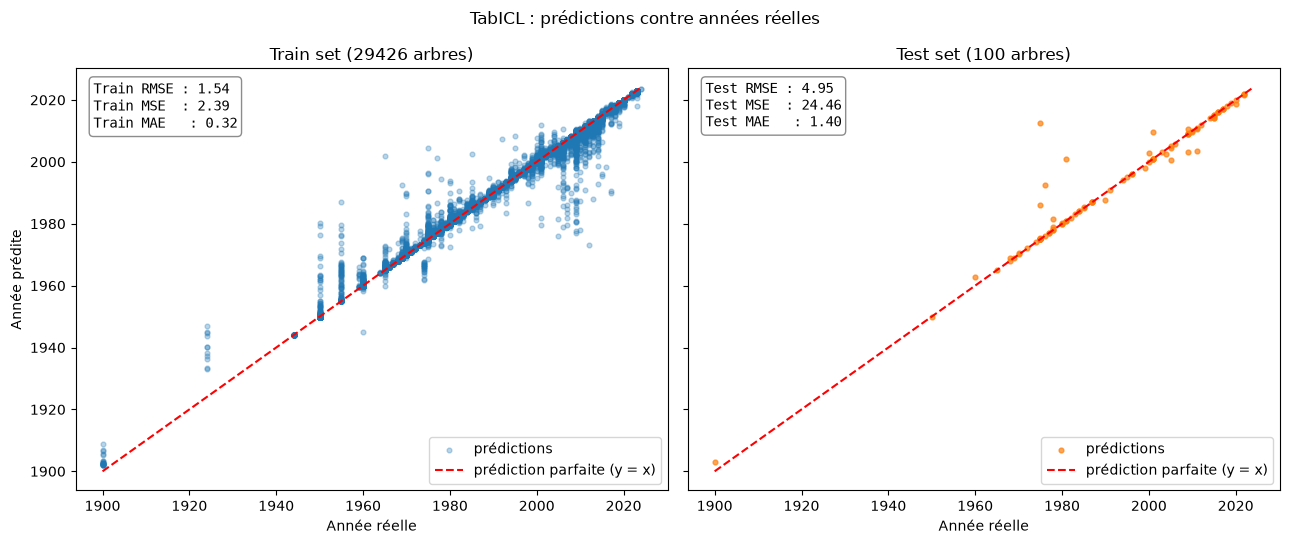

In [ ]:
# Métriques
metriques = {
    'Train': {'RMSE': root_mean_squared_error(y_train, y_pred_train),
              'MSE':  mean_squared_error(y_train, y_pred_train),
              'MAE':  mean_absolute_error(y_train, y_pred_train)},

    'Test':  {'RMSE': root_mean_squared_error(y_test, y_pred_test),
              'MSE':  mean_squared_error(y_test, y_pred_test),
              'MAE':  mean_absolute_error(y_test, y_pred_test)}
}

# Mêmes bornes pour les deux graphiques
lims = [min(y_train.min(), y_test.min()), max(y_train.max(), y_test.max())]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, (nom, y_vrai, y_pred, couleur) in zip(axes, [
        ('Train', y_train, y_pred_train, 'tab:blue'),
        ('Test',  y_test,  y_pred_test,  'tab:orange')]):

    ax.scatter(y_vrai, y_pred, alpha=0.3 if nom == 'Train' else 0.7, s=12, color=couleur, label='prédictions')
    ax.plot(lims, lims, 'r--', label='prédiction parfaite (y = x)')
    ax.set_title(f'{nom} set ({len(y_vrai)} arbres)')
    ax.set_xlabel('Année réelle')
    ax.legend(loc='lower right')

    # Bloc de texte avec les métriques
    texte = (f"{nom} RMSE : {metriques[nom]['RMSE']:.2f}\n"
             f"{nom} MSE  : {metriques[nom]['MSE']:.2f}\n"
             f"{nom} MAE   : {metriques[nom]['MAE']:.2f}")
    ax.text(0.03, 0.97, texte, transform=ax.transAxes, va='top', family='monospace',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray'))

axes[0].set_ylabel('Année prédite')
fig.suptitle('TabICL : prédictions contre années réelles')
plt.tight_layout()
plt.show()
